In [1]:
import os
import sys
import time

import joblib
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sys.path.insert(0, '../../..')
from utils.helper_functions import normalize_series
from utils.metrics import show_feature_extraction_metrics
from utils.plotting import plot_movement_data
from utils.constants import Configs
from scipy.stats import median_abs_deviation

TARGET_MOVEMENT = 'Move'

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.ICATER_ALL_SENSORS_FILTERED_DATA_DIR
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)

In [3]:
# Load the known outliers from the csv
outliers_csv = pd.read_csv(Configs.ICATER_OUTLIER_FILES).drop_duplicates(subset=['sub', 'repID'])
total_known_outliers = len(outliers_csv)

print(f"Total known outliers: {total_known_outliers}")
outliers_csv.head()

Total known outliers: 14


,sub,repID
0,2,2
1,4,1
2,5,2
3,5,5
4,7,1


In [4]:
cache_path = Configs.all_sensors_dtw_distance_matrix(TARGET_MOVEMENT)
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"DTW distance matrix for {TARGET_MOVEMENT} not found at {cache_path}. Please run the feature extraction notebook first.")   

dtw_matrix = joblib.load(cache_path)

In [5]:
# Load Times for benchmarking
times_path = Configs.ALL_SENSORS_DTW_CALCULATION_TIMES_CACHE
if not os.path.exists(times_path):
    raise FileNotFoundError(f"DTW calculation times not found at {times_path}. Please run the feature extraction notebook first.")

times = joblib.load(times_path)

In [6]:
group_array = ['xs', 'ys', 'zs', 'xe', 'ye', 'ze', 'xw', 'yw', 'zw']
sample_size = None

# Usar o TimeSeriesScalerMeanVariance para normalizar as séries temporais,
# mas sem escalar para zero média e unidade de variância (useScaler=False)
X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, n_features)

Processing time series: 100%|██████████| 95/95 [00:00<00:00, 3828.21it/s]

Shape of first series: (72, 9)
Shape of formatted series: (95, 196, 9)


## Z-Score (With the DTW Matrix)

### Teste de Normalidade
I cannot just simply throw a shapiro test hoping that will work. That test has a maximum ammount of features it can support, so, I will reduce the N x N matrix to a 1D array with N lenght, that, every cell has the mean of each line of the matrix. And with that array I will do a shapiro test.

In [7]:
import scipy.stats as stats

mean_distances = np.mean(dtw_matrix, axis=1)

stat, p_value = stats.shapiro(mean_distances)

print("--- Shapiro-Wilk Test Results ---")
print("---------------------------------")
print(f"{'Feature':<15} | {'P-Value':<12} | {'Conclusion'}")
is_normal = p_value > 0.05
conclusion = "Normal" if is_normal else "Not Normal"
print(f"{'Mean Distance':<15} | {p_value:.6f} | {conclusion}")


--- Shapiro-Wilk Test Results ---
---------------------------------
Feature         | P-Value      | Conclusion
Mean Distance   | 0.000001 | Not Normal


### Treinar Modelo

In [8]:
z_threshold = 3.0  # Normally is 3.5 for modified z-score

def modified_zscore(dtw_matrix):
    """
    Como aparentemente os meus dados não seguem uma distribuição normal, o Z-Score tradicional pode ser enganador.
    O Modified Z-Score é uma alternativa robusta que usa a mediana e o MAD (Median Absolute Deviation) em vez da média e do desvio padrão, tornando-o menos sensível a outliers.
    """

    mean_distances = np.mean(dtw_matrix, axis=1)  # Average distance per row
    
    # Use Median Absolute Deviation instead of std
    median = np.median(mean_distances)
    mad = median_abs_deviation(mean_distances)

    # Modified z-score (more robust to outliers)
    modified_z_scores = 0.6745 * (mean_distances - median) / mad

    outliers_indices = np.where(np.abs(modified_z_scores) > z_threshold)[0]

    return outliers_indices, modified_z_scores

start_time = time.perf_counter()

outlier_indices, modified_z_scores = modified_zscore(dtw_matrix)

end_time = time.perf_counter()
elapsed_time = end_time - start_time
elapsed_time_with_dtw = elapsed_time + times[TARGET_MOVEMENT]

n_outliers = len(outlier_indices)
X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
X_movement_outliers = X_movement[outlier_indices]

print(outlier_indices)
print(f"Total Analisado: {len(dtw_matrix)}")
print(f"Outliers Detetados (Z > {z_threshold}): {n_outliers}")
print(f"Percentagem de Lixo: {n_outliers/len(dtw_matrix)*100:.2f}%")
print(f"Percentagem de Retenção: {(len(dtw_matrix) - n_outliers)/len(dtw_matrix)*100:.2f}%")
print(f"Tempo de Execução do DBSCAN (sem DTW): {elapsed_time:.2f} segundos")
print(f"Tempo Total (DTW + DBSCAN): {elapsed_time_with_dtw:.2f} segundos")

[ 6 15]
Total Analisado: 95
Outliers Detetados (Z > 3.0): 2
Percentagem de Lixo: 2.11%
Percentagem de Retenção: 97.89%
Tempo de Execução do DBSCAN (sem DTW): 0.00 segundos
Tempo Total (DTW + DBSCAN): 2.35 segundos


In [9]:
# 1. Recriar a lista de identidades NA MESMA ORDEM que o X_movement foi gerado
# Nota: É crucial usar o mesmo filtro e ordem que usou no 'normalize_series'
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT]

# Agrupar pelas chaves únicas para obter a lista de movimentos
# sort=False preserva a ordem de aparição (geralmente mais seguro se não ordenou explicitamente antes)
grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()

# Criar um DataFrame auxiliar apenas com os Metadados (Índice 0 = 1º Movimento, Índice 1 = 2º Movimento...)
metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# 2. Merge dos Indíces do LOF com os Metadados
if len(metadata_df) != len(X_movement):
    print("⚠️ AVISO CRÍTICO: O número de movimentos não bate certo! Verifique a filtragem.")
else:
    # Filtrar o DataFrame de Metadados usando os índices do LOF
    real_outliers_info = metadata_df.iloc[outlier_indices]
    
    print("Quem são os outliers reais?")
    print(real_outliers_info)

Quem são os outliers reais?
    sub  repID  movID movLabel
6    11      2      9     Move
15    2      1      9     Move


In [10]:
# 1. Garantir que os outliers identificados também são únicos por sub e repID
# Assim, se um algoritmo deitar fora 3 'movID' da mesma 'repID', conta apenas como 1 True Positive
identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# 2. Cruzamento (Match)
matched_outliers = pd.merge(identified_unique, outliers_csv, on=['sub', 'repID'], how='inner')

# 3. Encontrar os que falharam (Missing / False Negatives)
missing_outliers = pd.merge(outliers_csv, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

# --- CÁLCULO DAS MÉTRICAS ---
metrics = show_feature_extraction_metrics(
    metadata_df,
    outliers_csv,
    identified_unique,
    matched_outliers,
    missing_outliers
)

--- MATRIZ DE CONFUSÃO (Baseada em sub+repID) ---
True Positives (Identificados e no CSV) : 0
False Positives (Identificados, não CSV): 2
False Negatives (No CSV, não identificados): 14
True Negatives (Normais, mantidos normais): 79
--------------------------------------------------
Missing outliers (Escaparam ao algoritmo):
    sub  repID
0     2      2
1     4      1
2     5      2
3     5      5
4     7      1
5     8      1
6     9      1
7    11      1
8    12      1
9    13      1
10   16      1
11   16      5
12   18      2
13   19      2

Precision (Precisão) (Falsos Alarmes): 0/2 (0.00%)
Recall (Taxa de Acerto): 0/14 (0.00%)
F1-Score: 0.00%
F2-Score: 0.00%


A desenhar trajetórias do Ombro...


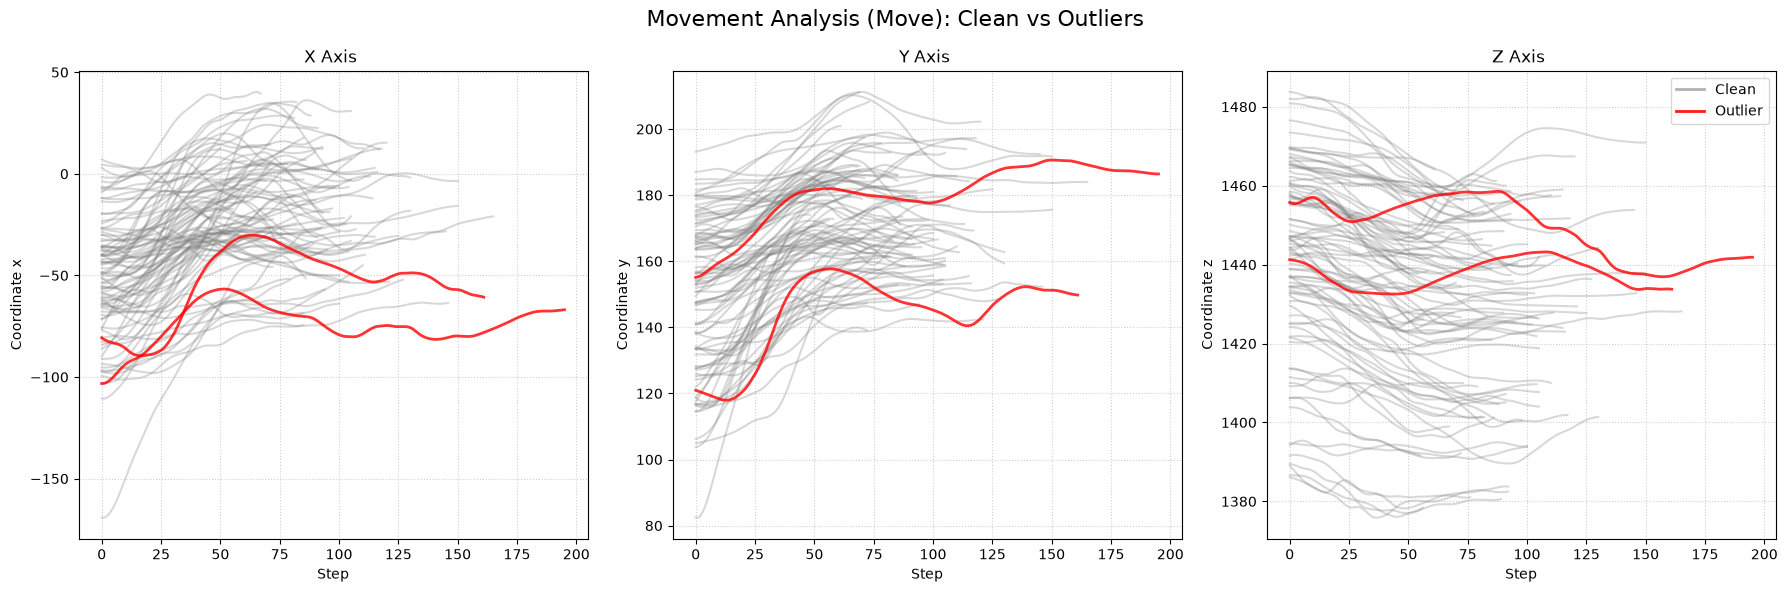

A desenhar trajetórias do Cotovelo...


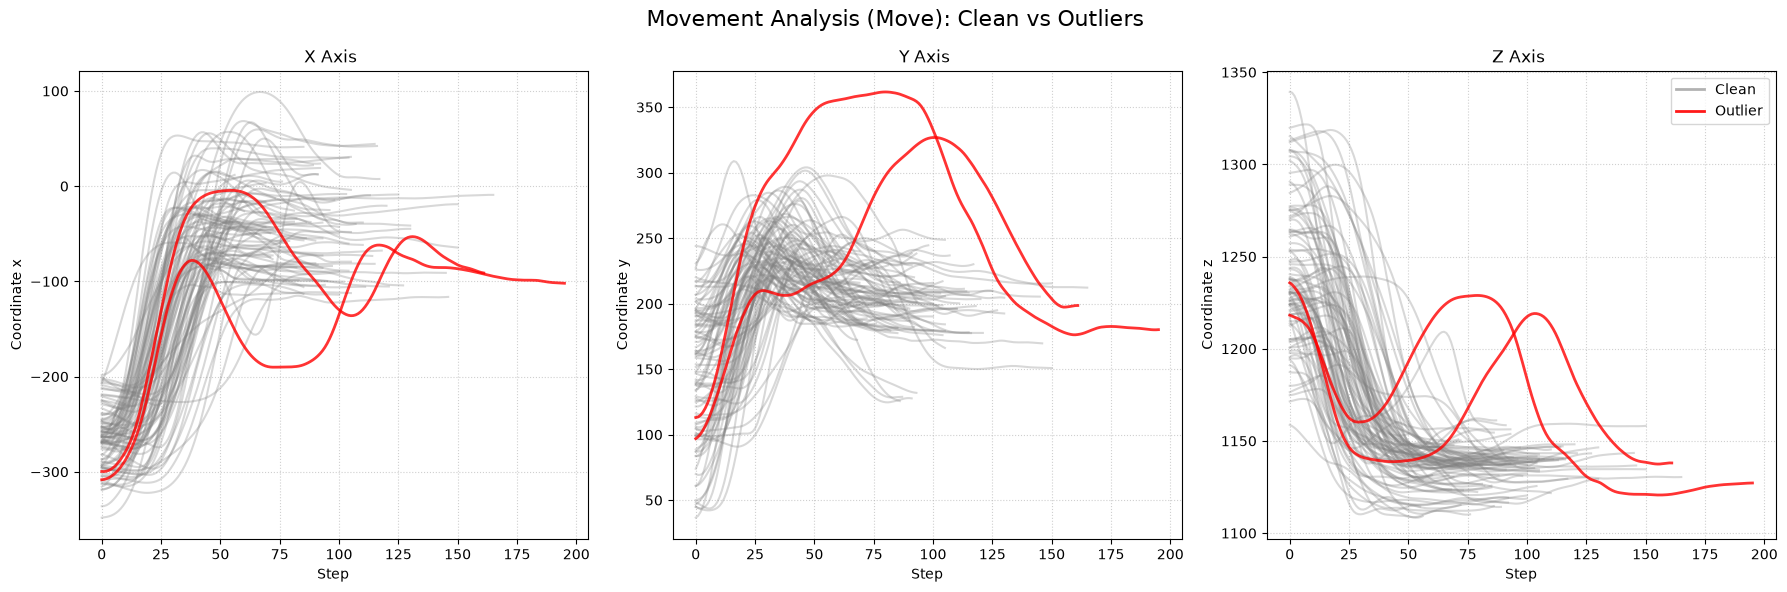

A desenhar trajetórias do Pulso...


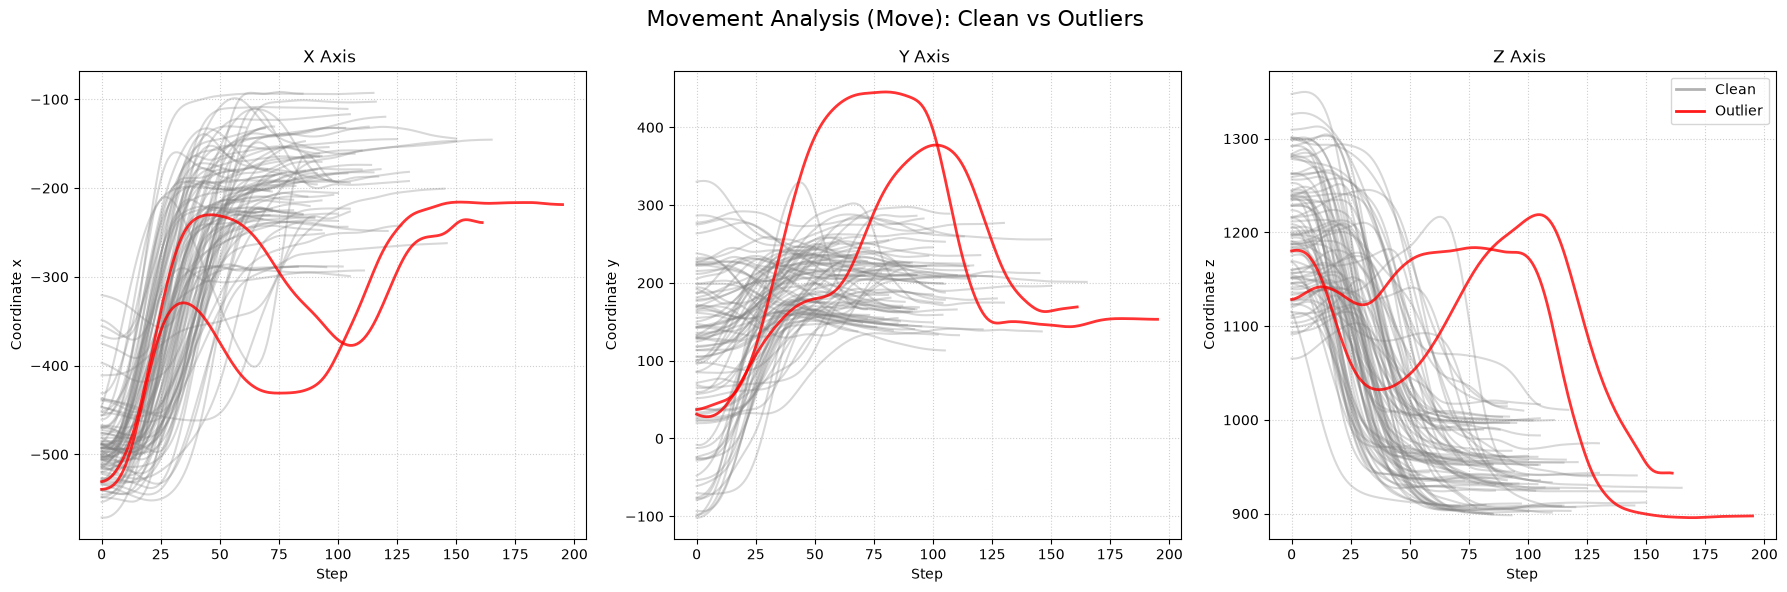

In [11]:
# 1. Ver as trajetórias do Ombro (Índices 0, 1, 2)
print("A desenhar trajetórias do Ombro...")
plot_movement_data(X_movement_clean[:, :, 0:3], X_movement_outliers[:, :, 0:3], TARGET_MOVEMENT)

# 2. Ver as trajetórias do Cotovelo (Índices 3, 4, 5)
print("A desenhar trajetórias do Cotovelo...")
plot_movement_data(X_movement_clean[:, :, 3:6], X_movement_outliers[:, :, 3:6], TARGET_MOVEMENT)

# 3. Ver as trajetórias do Pulso/Mão (Índices 6, 7, 8)
print("A desenhar trajetórias do Pulso...")
plot_movement_data(X_movement_clean[:, :, 6:9], X_movement_outliers[:, :, 6:9], TARGET_MOVEMENT)